# Q1

![Eq 4.1](ch4_images/4-1.png)


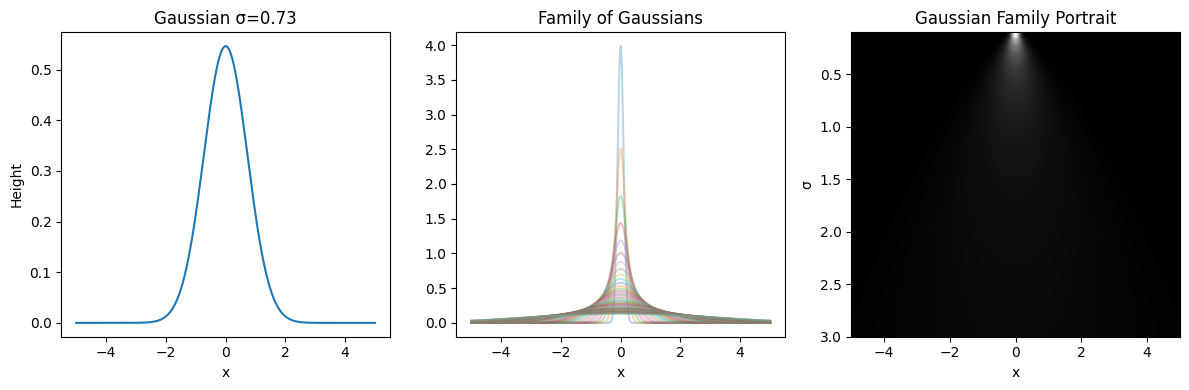

In [2]:
import matplotlib.pyplot as plt
import numpy as np


# 1. Equation 4.1
def gaussian(x, sigma):
    x = np.array(x)[None, :]  # (1, N)
    sigma = np.array(sigma)[:, None]  # (M, 1)

    exp_term = -(x ** 2) / (2 * sigma ** 2)
    denom = sigma * np.sqrt(2 * np.pi)
    return np.exp(exp_term) / denom
    # return np.exp(exp_term)


sigma = 0.73
N = 1000
x = np.linspace(-5, 5, N)
y = gaussian(x, [sigma])[0]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(x, y)
plt.title(f"Gaussian σ={sigma}")
plt.xlabel("x")
plt.ylabel("Height")

# 2. a family of Gaussians
sigmas = np.linspace(0.1, 3.0, 50)
family = gaussian(x, sigmas)

plt.subplot(1, 3, 2)
plt.plot(x, family.T, alpha=0.3)
plt.title("Family of Gaussians")
plt.xlabel("x")

# 3. Gaussian family portrait (heatmap)
plt.subplot(1, 3, 3)

plt.imshow(
    family,
    aspect='auto',
    cmap='gray',
    extent=[x.min(), x.max(), sigmas.max(), sigmas.min()]
)

plt.title("Gaussian Family Portrait")
plt.xlabel("x")
plt.ylabel("σ")

plt.tight_layout()
plt.show()

# Q2

In [3]:
# sum
sum_for_gaussians = np.sum(family, axis=1)
print(sum_for_gaussians)

# discrete integral
dx = x[1] - x[0]
integral = family @ (np.ones_like(x) * dx)
print(integral)

[99.9        99.9        99.9        99.9        99.9        99.9
 99.9        99.9        99.9        99.9        99.9        99.9
 99.89999993 99.89999914 99.89999296 99.89995964 99.89982543 99.89939618
 99.89825502 99.89564262 99.8903498  99.88065288 99.86431134 99.83863117
 99.80058243 99.74695103 99.67450199 99.58013477 99.46101615 99.31468273
 99.13911016 98.93275061 98.69454238 98.42389697 98.12066914 97.78511552
 97.41784615 97.01977296 96.59205802 96.13606377 95.65330666 95.14541509
 94.61409208 94.06108292 93.48814748 92.89703713 92.28947579 91.66714466
 91.03167037 90.38461593]
[1.         1.         1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.
 1.         0.99999999 0.99999993 0.9999996  0.99999825 0.99999396
 0.99998253 0.99995638 0.9999034  0.99980634 0.99964276 0.9993857
 0.99900483 0.99846798 0.99774276 0.99679815 0.99560577 0.99414097
 0.99238349 0.99031782 0.98793336 0.98522419 0.98218888 0.97882999
 0.97515362 0.97116

- "The Gaussians are designed to integrate to 1. But why do only
the first few Gaussians sum to 1 while the later Gaussians
sum to less than 1? The answer is that a true Gaussian is
defined from x = −∞ to x = +∞; a restricted domain is not
guaranteed to integrate to 1."
- "Finally, remove the multiplicative factor in the beginning of
the equation, and reproduce Figure 4.29 and the integral above.
Now the sums don’t equal 1, but all Gaussians have a peak
value of 1. There’s nothing wrong with this result; there are
different ways to normalize data and functions, and different
normalizations have different implications and are appropri-
ate for different situations."

# Q3

In [42]:
def desc_stat(x):
    mean = sum(x) / len(x)

    x_sorted = sorted(x)
    n = len(x)
    if n % 2 == 1:
        median = x_sorted[n // 2]
    else:
        median = (x_sorted[n // 2 - 1] + x_sorted[n // 2]) / 2

    variance = sum((i - mean) ** 2 for i in x) / (len(x) - 1)
    return mean, median, variance


x = [1, 7, 2, 7, 3, 7, 4, 7, 5, 7, 6, 7]
mean, median, var = desc_stat(x)


# numpy
def np_desc_stat(x):
    mean_np = np.mean(x)
    median_np = np.median(x)
    var_np = np.var(x, ddof=1)  # denominator degrees of freedom
    return mean_np, median_np, var_np


mean_np, median_np, var_np = np_desc_stat(x)

print(f"Mine: {mean}, {median}, {var:.2f}")
print(f"Numpy: {mean_np}, {median_np}, {var_np:.2f}")

ran_x = np.random.randint(4, 20, size=24)
print(ran_x)

mean, median, var = desc_stat(ran_x)
mean_np, median_np, var_np = np_desc_stat(ran_x)

print(f"Mine: {mean:.2f}, {median}, {var:.2f}")
print(f"Numpy: {mean_np:.2f}, {median_np}, {var_np:.2f}")

Mine: 5.25, 6.5, 4.93
Numpy: 5.25, 6.5, 4.93
[10  4 12  7  9 17 17  5  7 13  6 11 19  4 13 19  4  8 11 12  6  9 13  7]
Mine: 10.12, 9.5, 21.51
Numpy: 10.12, 9.5, 21.51


# Q4
Does it really matter if you use the population or the
sample variance (that is, if you divide by N or N − 1)?

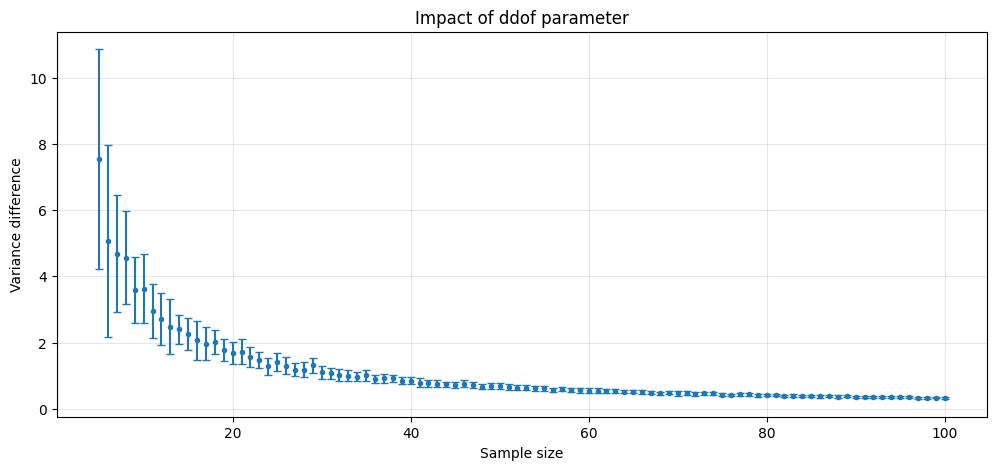

In [55]:
def var_experiment(n=25):
    sizes = np.arange(5, 101, 1, dtype=np.int32)
    error_hist = np.zeros((n, sizes.shape[0]))

    for idx, s in enumerate(sizes):
        for i in range(n):
            sample = np.random.randint(-10, 10, size=s)
            pop_var = np.var(sample)
            sam_var = np.var(sample, ddof=1)
            error_hist[i, idx] = sam_var - pop_var

    return sizes, error_hist


sizes, error_hist = var_experiment(n=25)

mean_error = np.mean(error_hist, axis=0)
std_error = np.std(error_hist, axis=0)

plt.figure(figsize=(12, 5))
plt.errorbar(sizes, mean_error, yerr=std_error, fmt='o', markersize=3, capsize=3)
plt.xlabel("Sample size")
plt.ylabel("Variance difference")
plt.title("Impact of ddof parameter")
plt.grid(alpha=0.3)
plt.show()

- "Three observations from this result. First, the impact of the
ddof parameter decreases with increasing sample size. Second,
the error bars indicate that different repetitions of the same
experiment give different results, especially with smaller sam-
ple sizes."
- "Third, the differences in variances are in the 200-600 range
for relatively small sample sizes. Is that a "big" difference?
Repeat the experiment but use numbers between -10 and +10.
The y-axis values are now much smaller. In other words, it is
difficult to draw conclusions based on the numerical values
because they depend on the range of the data values. Perhaps
we could gain a deeper understanding of the plot if we could
apply some normalization (segue to the next exercise)..."

# Q5

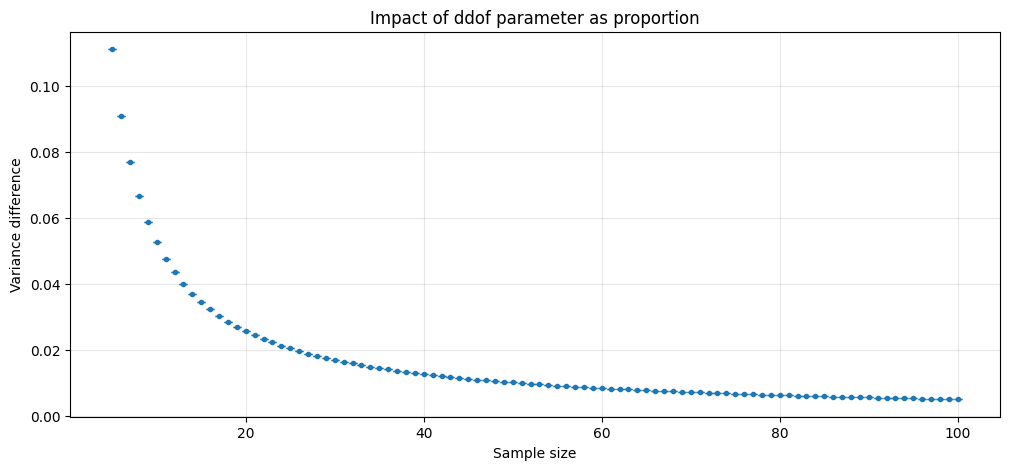

In [57]:
def var_experiment(n=25):
    sizes = np.arange(5, 101, 1, dtype=np.int32)
    error_hist = np.zeros((n, sizes.shape[0]))

    for idx, s in enumerate(sizes):
        for i in range(n):
            sample = np.random.randint(-100, 100, size=s)
            pop_var = np.var(sample)
            sam_var = np.var(sample, ddof=1)
            error_hist[i, idx] = (sam_var - pop_var) / (sam_var + pop_var)

    return sizes, error_hist


sizes, error_hist = var_experiment(n=25)

mean_error = np.mean(error_hist, axis=0)
std_error = np.std(error_hist, axis=0)

plt.figure(figsize=(12, 5))
plt.errorbar(sizes, mean_error, yerr=std_error, fmt='o', markersize=3, capsize=3)
plt.xlabel("Sample size")
plt.ylabel("Variance difference")
plt.title("Impact of ddof parameter as proportion")
plt.grid(alpha=0.3)
plt.show()

- "Are you surprised that the error bars are so small? In fact,
the standard deviation across experiment repetitions is zero
because the proportion values are identical, even though the
data values are randomly changing."
- "It turns out that the impact of degrees of freedom on the scaled
variance difference equals 1/(2N − 1), i.e., it is entirely deter-
mined by the sample size and has nothing to do with the data."

# Q6
Let’s explore the impact of a single outlier on the mean vs. median, for large and small sample sizes.

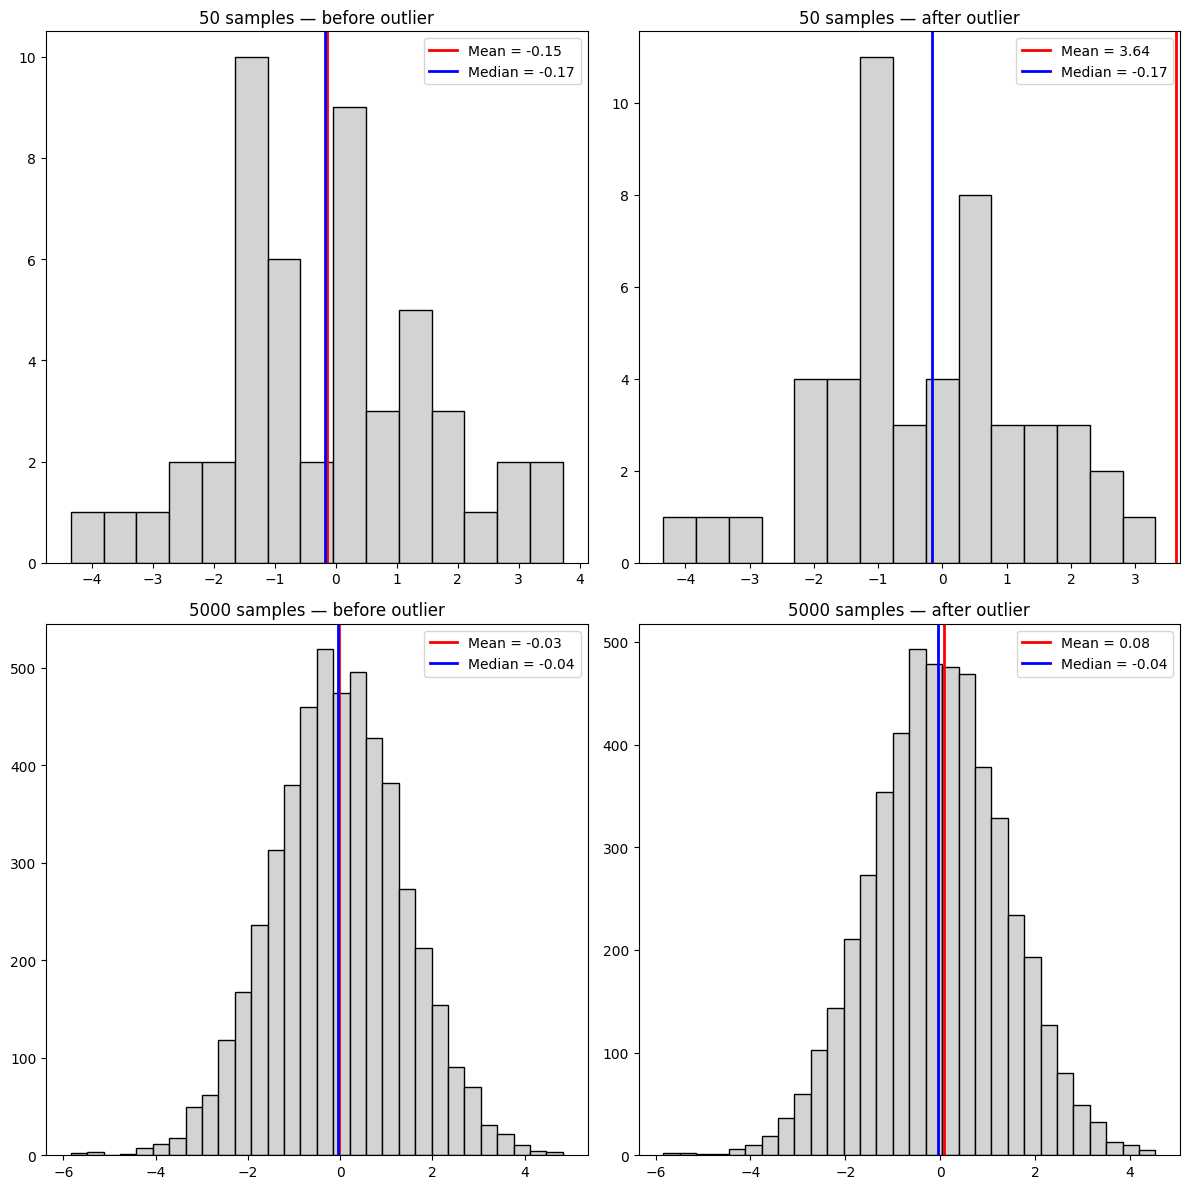

50 samples: mean shift = 3.784867551089848   median shift = 0.0
5000 samples: mean shift = 0.10787134394462097   median shift = 0.0


In [8]:
plt.figure(figsize=(12, 12))

#  PART 1 — 50 samples
sample1 = np.random.normal(scale=np.sqrt(2), size=50)
mean1 = np.mean(sample1)
median1 = np.median(sample1)

# Panel A — Before outlier
plt.subplot(2, 2, 1)
plt.hist(sample1, bins=15, color="lightgray", edgecolor="black")
plt.axvline(mean1, color='red', linewidth=2, label=f"Mean = {mean1:.2f}")
plt.axvline(median1, color='blue', linewidth=2, label=f"Median = {median1:.2f}")
plt.title("50 samples — before outlier")
plt.legend()

# Panel B — After adding outlier
sample1_out = sample1.copy()
sample1_out[sample1_out.argmax()] **= 4  # x_max = x_max^4
sample1_out_plot = sample1_out[sample1_out != sample1_out.max()]
mean1_out = np.mean(sample1_out)
median1_out = np.median(sample1_out)

plt.subplot(2, 2, 2)
plt.hist(sample1_out_plot, bins=15, color="lightgray", edgecolor="black")
plt.axvline(mean1_out, color='red', linewidth=2, label=f"Mean = {mean1_out:.2f}")
plt.axvline(median1_out, color='blue', linewidth=2, label=f"Median = {median1_out:.2f}")
plt.title("50 samples — after outlier")
plt.legend()

#  PART 2 — 5000 samples
sample2 = np.random.normal(scale=np.sqrt(2), size=5000)
mean2 = np.mean(sample2)
median2 = np.median(sample2)

# Panel C — Before outlier
plt.subplot(2, 2, 3)
plt.hist(sample2, bins=30, color="lightgray", edgecolor="black")
plt.axvline(mean2, color='red', linewidth=2, label=f"Mean = {mean2:.2f}")
plt.axvline(median2, color='blue', linewidth=2, label=f"Median = {median2:.2f}")
plt.title("5000 samples — before outlier")
plt.legend()

# Panel D — After outlier
sample2_out = sample2.copy()
sample2_out[sample2_out.argmax()] **= 4
sample2_out_plot = sample2_out[sample2_out != sample2_out.max()]
mean2_out = np.mean(sample2_out)
median2_out = np.median(sample2_out)

plt.subplot(2, 2, 4)
plt.hist(sample2_out_plot, bins=30, color="lightgray", edgecolor="black")
plt.axvline(mean2_out, color='red', linewidth=2, label=f"Mean = {mean2_out:.2f}")
plt.axvline(median2_out, color='blue', linewidth=2, label=f"Median = {median2_out:.2f}")
plt.title("5000 samples — after outlier")
plt.legend()

plt.tight_layout()
plt.show()

#  PRINT SHIFTS
print("50 samples: mean shift =", mean1_out - mean1,
      "  median shift =", median1_out - median1)

print("5000 samples: mean shift =", mean2_out - mean2,
      "  median shift =", median2_out - median2)


- "Some observations: The median was completely unaffected by
the outlier. That’s not surprising because we replaced the
largest value with an even-larger value; in other words, we
changed a numerical value but did not change its position rel-
ative to the midpoint of the data. It’s not surprising that the
mean was pulled up by the outlier, but it is interesting to see
that the impact was much smaller when the sample size was larger."

# Q7
The purpose of this exercise is to use code to compute the
statistical moments of various distributions.

In [7]:
from scipy import stats

mean, variance, skew, kurtosis = stats.norm.stats(loc=1, scale=2, moments="mvsk")
print(mean, variance, skew, kurtosis)

1.0 4.0 0.0 0.0


# Q8
In this exercise, you will explore how statistical moments are
impacted by the change in a distribution.

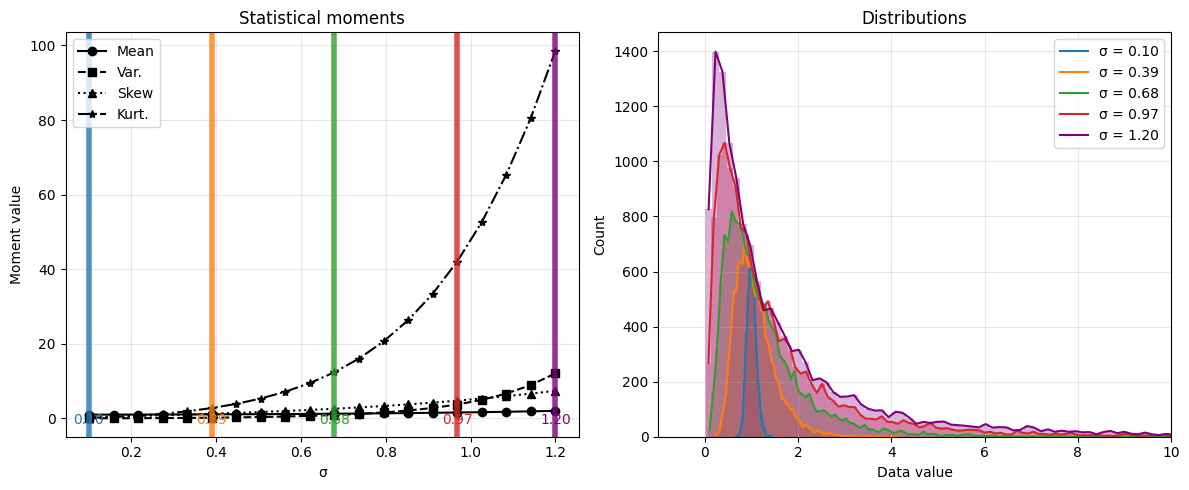

In [8]:
def my_mvsk(x):
    m = np.mean(x)
    v = np.var(x, ddof=1)
    s = stats.skew(x)
    k = stats.kurtosis(x)
    return m, v, s, k


N = 13524
sample = np.random.normal(size=N)
sigmas = np.linspace(0.1, 1.2, 20)
datasets = [np.exp(sample * s) for s in sigmas]

# --- plot A ---
means = np.zeros(20)
variances = np.zeros(20)
skews = np.zeros(20)
kurts = np.zeros(20)

for i, data in enumerate(datasets):
    means[i], variances[i], skews[i], kurts[i] = my_mvsk(data)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(sigmas, means, 'ko-', label="Mean")
plt.plot(sigmas, variances, 'ks--', label="Var.")
plt.plot(sigmas, skews, 'k^:', label="Skew")
plt.plot(sigmas, kurts, 'k*-.', label="Kurt.")

plt.xlabel("σ")
plt.ylabel("Moment value")
plt.title("Statistical moments")
plt.grid(alpha=0.3)
plt.legend()

# Mark selected σ values (0.10, 0.33, 0.62, 0.91, 1.20)
selected_idx = [0, 5, 10, 15, 19]

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "purple"]

for c, idx in zip(colors, selected_idx):
    x = sigmas[idx]
    y = 0
    plt.axvline(x, color=c, linewidth=4, alpha=0.8)
    plt.text(x, -1.5, f"{x:.2f}", ha='center', color=c)

# =========================
#     FIGURE 4.33B
# =========================
plt.subplot(1, 2, 2)


def fd_bins(y):
    q75, q25 = np.percentile(y, [75, 25])
    iqr = q75 - q25
    bw = 2 * iqr / (len(y) ** (1 / 3))
    return int((y.max() - y.min()) / bw)


for c, idx in zip(colors, selected_idx):
    data = datasets[idx]
    bins = fd_bins(data)
    plt.hist(data, bins=bins, alpha=0.3, color=c, density=False)

    # Overlay density-like curve using histogram counts
    counts, edges = np.histogram(data, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    plt.plot(centers, counts, color=c, label=f"σ = {sigmas[idx]:.2f}")

plt.xlabel("Data value")
plt.ylabel("Count")
plt.xlim(-1, 10)
plt.title("Distributions")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Q9
- IQR and standard deviation are conceptually similar — both
relate to the spread of data around their central tendency (me-
dian for IQR; mean for standard deviation). In fact, for a
normal distribution, IQR is approximately 1.35σ.

In [3]:
def fd_bins(y):
    q75, q25 = np.percentile(y, [75, 25])
    iqr = q75 - q25
    bw = 2 * iqr / (len(y) ** (1 / 3))
    return int((y.max() - y.min()) / bw)

1.00, 1.38
2.09, 1.51
0.7229619091909623


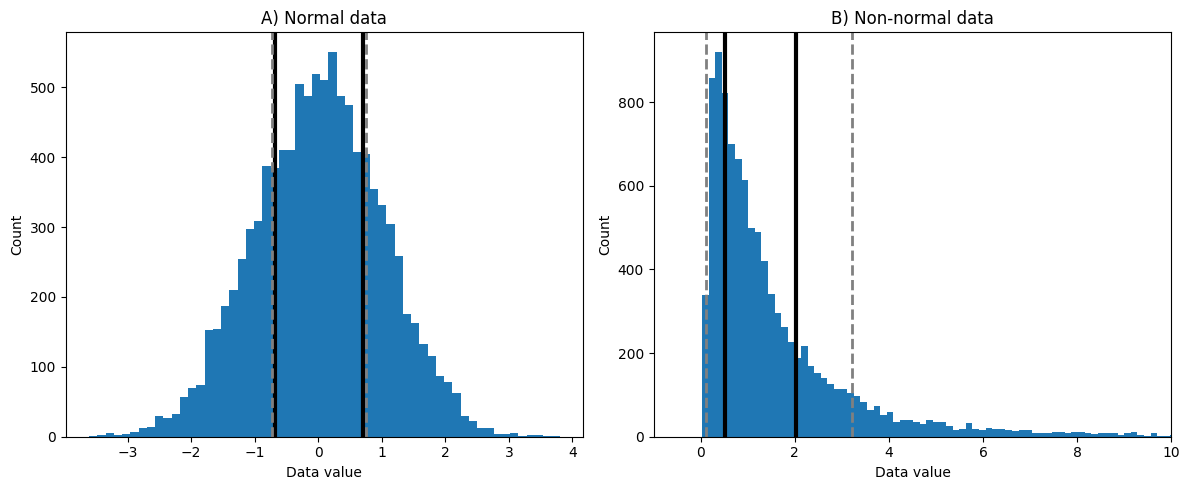

In [9]:
sample = np.random.normal(size=10000)
std = np.sqrt(np.var(sample, ddof=1))

q75, q25 = np.percentile(sample, [75, 25])
iqr = q75 - q25
print(f"{std:.2f}, {iqr:.2f}")

exp = np.exp(sample)
std = np.sqrt(np.var(exp, ddof=1))

q75, q25 = np.percentile(exp, [75, 25])
iqr = q75 - q25
print(f"{std:.2f}, {iqr:.2f}")
print(iqr / std)


def stats_for(x):
    mean = np.mean(x)
    std = np.sqrt(np.var(x, ddof=1))
    q75, q25 = np.percentile(x, [75, 25])
    return mean, std, q25, q75


mean1, std1, q1_1, q3_1 = stats_for(sample)
mean2, std2, q1_2, q3_2 = stats_for(exp)

# Plot Figure 4.34
plt.figure(figsize=(12, 5))

# ---- Panel A: Normal ----
plt.subplot(1, 2, 1)
plt.hist(sample, bins=fd_bins(sample))

# quartile lines
plt.axvline(q1_1, color='black', linewidth=3)
plt.axvline(q3_1, color='black', linewidth=3)

# dashed std/1.35 lines
plt.axvline(mean1 - std1 / 1.35, color='gray', linestyle='--', linewidth=2)
plt.axvline(mean1 + std1 / 1.35, color='gray', linestyle='--', linewidth=2)

plt.title("A) Normal data")
plt.xlabel("Data value")
plt.ylabel("Count")

# ---- Panel B: Non-normal ----
plt.subplot(1, 2, 2)
plt.hist(exp, bins=fd_bins(exp))

# quartile lines
plt.axvline(q1_2, color='black', linewidth=3)
plt.axvline(q3_2, color='black', linewidth=3)

# dashed std/1.35 lines
plt.axvline(mean2 - std2 / 1.35, color='gray', linestyle='--', linewidth=2)
plt.axvline(mean2 + std2 / 1.35, color='gray', linestyle='--', linewidth=2)

plt.title("B) Non-normal data")
plt.xlabel("Data value")
plt.ylabel("Count")
plt.xlim(-1, 10)

plt.tight_layout()
plt.show()

- Some observations: (1) For a normal distribution (panel A),
the quartiles and standard deviation are comparably far away
from the center of the distribution (not surprising, considering
that the mean and median are nearly the same, and that the
distribution is symmetric). (2) For a non-normal distribution
(panel B), the quartiles and standard deviation are more dis-
similar, because the mean and median are further from each
other. (3) For the non-normal distribution, the standard
deviation is difficult to interpret — indeed, the standard de-
viation below the mean is negative despite the dataset being
entirely positive-valued.

# Q10
The goal of this exercise is to develop an algorithm to compute
the empirical FWHM of a Gaussian-like distribution.

![Eq 4.10](ch4_images/4-10.png)

4.48
4.474158085558804


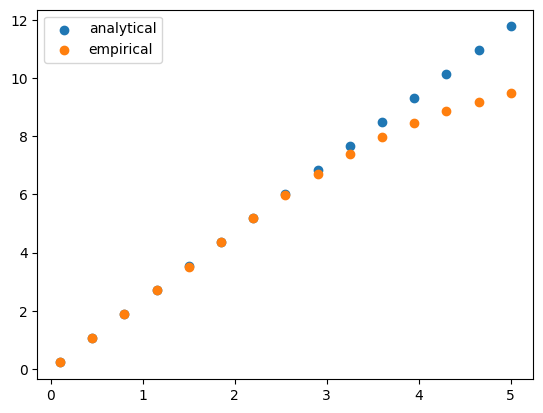

In [26]:
def empFWHM(x, y):
    # normalize
    y_tilde = (y - np.min(y)) / (np.max(y) - np.min(y))
    # find the peak
    idx_peak = np.argmax(y_tilde)
    # find the pre-peak half-maximum point
    pre_hm_idx = np.argmin(np.abs(y_tilde[:idx_peak + 1] - 0.5))
    # find the post-peak half-maximum point
    post_hm_idx = np.argmin(np.abs(y_tilde[idx_peak:] - 0.5)) + idx_peak
    fwhm = x[post_hm_idx] - x[pre_hm_idx]
    return fwhm, x[post_hm_idx], x[pre_hm_idx]


def g(x, sigma):
    return np.exp(-x ** 2 / (2 * sigma ** 2))


def FWHM(sigma):
    return 2 * sigma * np.sqrt(2 * np.log(2))


sigma = 1.9
x = np.linspace(-8, 8, 1001)

print(empFWHM(x, g(x, sigma))[0])
print(FWHM(sigma))

sigmas = np.linspace(0.1, 5, 15)
emp_fwhms = []
fwhms = []

for s in sigmas:
    emp_fwhms.append(empFWHM(x, g(x, s))[0])
    fwhms.append(FWHM(s))

plt.scatter(sigmas, fwhms, label="analytical")
plt.scatter(sigmas, emp_fwhms, label="empirical")
plt.legend()
plt.show()

The problem is that the later Gaussians don't have a wide enough x-axis range,
so the normalization distorts the Gaussian.

Empirical FWHM: 2.338708081191765


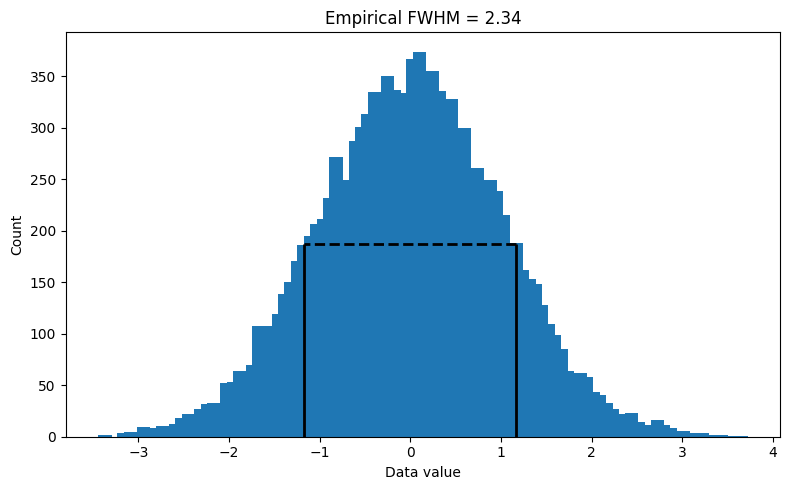

In [29]:
sample = np.random.normal(size=12345)
y, x = np.histogram(sample, bins=100)
x_centers = (x[:-1] + x[1:]) / 2

fwhm, left, right = empFWHM(x_centers, y)

print("Empirical FWHM:", fwhm)

plt.figure(figsize=(8, 5))

# histogram as bars
plt.bar(x_centers, y, width=edges[1] - edges[0])

# dashed horizontal line at half max
half_height = (np.max(y) - np.min(y)) * 0.5 + np.min(y)
plt.hlines(half_height, left, right, colors='black', linestyles='dashed', linewidth=2)

# also show the two vertical half-max points
plt.vlines([left, right], ymin=0, ymax=half_height, color='black', linewidth=2)

plt.title(f"Empirical FWHM = {fwhm:.2f}")
plt.xlabel("Data value")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

# Q11
The purpose of this exercise is to explore the implications of
different histogram bin rules on the visual appearance of a
distribution.

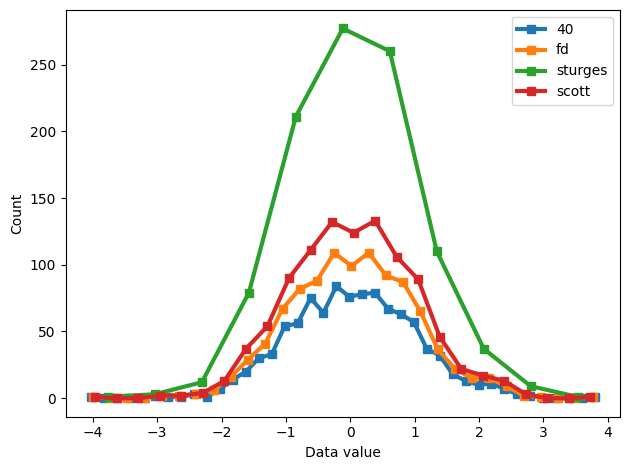

In [33]:
sample = np.random.normal(size=1000)

bin_opt = [40, 'fd', 'sturges', 'scott']

for bin in bin_opt:
    y, x = np.histogram(sample, bins=bin)
    x_centers = (x[:-1] + x[1:]) / 2
    plt.plot(x_centers, y, 's-', linewidth=3, label=bin)

plt.legend()
plt.xlabel('Data value')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

- Some binnings give "taller" distributions, because they have fewer bins;
fewer bins means more data points per bin.
   
- "One important take-home message from this exercise is that
the method you choose to select the number of histogram bins
usually doesn’t make a qualitative impact on the results. That
is, the different rules have a numerical impact, but would not
change the qualitative interpretation of the data."